Practice: linear fit

No one in their right mind would fit data to a line this way. The purpose of this is to understand how fit() and predict() can work, so we can use it later in the Perceptron. 

In [1]:
import numpy as np
import scipy 
class Line():

 def __init__(self):
    self.slope = None
    self.intercept = None
 def linear(self, x, slope, intercept):
    return slope * x + intercept
 
 def fit(self, X, y): # X is a numpy aray
    params, param_covs = scipy.optimize.curve_fit(self.linear, X, y)
    self.slope, self.intercept = params[0], params[1]
    return self
 def __str__(self):
    slope_str = "{:.2f}".format(self.slope)
    intercept_str = "{:.2f}".format(self.intercept)
    return f"y = {slope_str}x + {intercept_str }"
 def predict(self, X):
    return self.slope * X + self.intercept

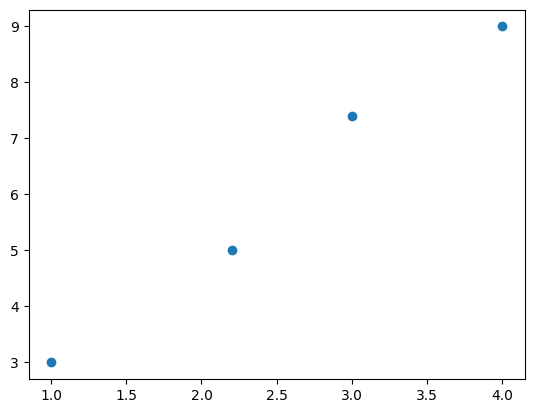

In [2]:
import matplotlib.pyplot as plt
X = np.array([1.0, 2.2, 3.0, 4.0])
Y = np.array([3.0, 5.0, 7.40, 9.0])
plt.scatter(X, Y)
plt.show()

Perceptron

In [3]:
model = Line()
model.fit(X, Y)
print(model) 

y = 2.07x + 0.83


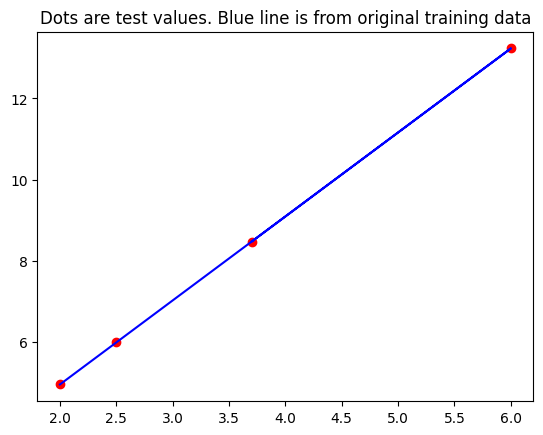

In [4]:
X_test = np.array([2.0, 2.5, 6.0, 3.7])
Y_pred = model.predict(X_test)
plt.scatter(X_test, Y_pred, color='red')
slope = model.slope
intercept = model.intercept
plt.plot(X_test, slope * X_test + intercept, color='blue')
plt.title("Dots are test values. Blue line is from original training data")
plt.show()

In [42]:
 
class Perceptron:
 """
 Parameters
 ------------
 eta : float
 Learning rate (between 0.0 and 1.0)
 n_iter : int
 Passes over the training dataset.
 random_state : int
 Random number generator seed for random weight initialization.

 Attributes
 -----------
 w_ : 1d-array
 Weights after fitting.
 b_ : Scalar
 Bias unit after fitting.
 errors_ : list
 Number of misclassifications (updates) in each epoch.
 """
 def __init__(self, eta=0.05, n_iter=50, random_state=1):
    self.eta = eta
    self.n_iter = n_iter
    self.random_state = random_state


 def fit(self, X, y):
    """
    X : {array-like}, shape = [n_examples, n_features]
    Training vectors, where n_examples is the number of
    examples and n_features is the number of features.
    y : array-like, shape = [n_examples]
    Target values.
    """  
    rgen = np.random.RandomState(self.random_state)
    self.w_ = rgen.normal(loc=0.0, scale=0.01,size=X.shape[1])
    self.b_ = np.float64(0.)
    self.errors_ = []

    for _ in range(self.n_iter):
      errors = 0
      for xi, target in zip(X, y):
         update = self.eta * (target - self.predict(xi))
         self.w_ += update * xi
         self.b_ += update
         errors += int(update != 0.0)
      self.errors_.append(errors)
    return self

 def net_input(self, X):
    """Calculate net input"""
    return np.dot(X, self.w_) + self.b_

 def predict(self, X):
    """Return class label after unit step"""
    return np.where(self.net_input(X) >= 0.0, 1, 0)

[2, 3, 1, 0]


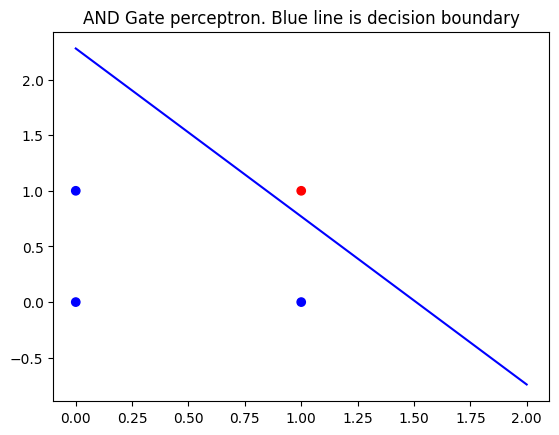

: 

In [ ]:
model = Perceptron(n_iter = 4)
X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
y = np.array([0, 0, 0, 1])
model.fit(X, y)
print(model.errors_)
x1 = X[:,0]
x2 = X[:,1]
plt.scatter(x1,x2,c=y,cmap='bwr')
x= np.linspace(0,2,50)
plt.plot(x, -(model.w_[0]/model.w_[1])*x- model.b_/model.w_[1], color='blue')
plt.title("AND Gate perceptron. Blue line is decision boundary")
plt.show()
